## Initialize

In [1]:

from pathlib import Path

from keras.preprocessing import image_dataset_from_directory

from sklearn.utils.class_weight import compute_class_weight

from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from keras import layers

from keras.applications import MobileNetV2

import kagglehub

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.metrics import confusion_matrix

import numpy as np

import keras

from sklearn.metrics import f1_score, roc_auc_score

2026-10-20 20:38:24.184008: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792528704.226722    1425 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792528704.239656    1425 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792528704.305469    1425 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792528704.305493    1425 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792528704.305495    1425 computation_placer.cc:177] computation placer alr

In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
path = Path(path)

100%|██████████| 2.29G/2.29G [01:22<00:00, 29.7MB/s]

Extracting files...


In [3]:
train_directory =  path / "chest_xray" / "chest_xray" / "train"

val_directory =  path / "chest_xray" / "chest_xray" / "val"

test_directory =  path / "chest_xray" / "chest_xray" / "test"

In [4]:


train_ds = image_dataset_from_directory(
    train_directory,
    labels="inferred",
    label_mode = 'binary', # should be like loss in model
    color_mode="rgb",
    batch_size=32,
    shuffle=True,
    seed = 42, # like random_state
)

val_ds = image_dataset_from_directory(
    train_directory,
    labels="inferred",
    label_mode = 'binary', # should be like loss in model
    color_mode="rgb",
    batch_size=32,
    shuffle=True,
    seed = 42, # like random_state
)

test_ds = image_dataset_from_directory(
    train_directory,
    labels="inferred",
    label_mode = 'binary', # should be like loss in model
    color_mode="rgb",
    batch_size=32,
    shuffle=True,
    seed = 42, # like random_state
)



Found 5216 files belonging to 2 classes.


I0000 00:00:1792528831.891277    1425 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10521 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1080 Ti, pci bus id: 0000:04:00.0, compute capability: 6.1


Found 5216 files belonging to 2 classes.
Found 5216 files belonging to 2 classes.


In [5]:



def class_weight():
    

    y_train = np.concatenate([
    labels.numpy()
    for images, labels in train_ds
    ]).flatten()
    
    classes = np.asarray(np.unique(y_train), dtype=np.int16)

    computed_class_weight = compute_class_weight(class_weight="balanced", classes=classes, y = y_train)

    class_weights = dict(zip(classes, computed_class_weight))

    return class_weights

computed_class_weight = class_weight()

2026-10-20 20:40:44.356591: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [6]:
early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

checkpoint = ModelCheckpoint(
    "best_pneumonia_model.keras",
    monitor="val_loss",
    save_best_only=True
)


reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=2,
    min_lr=1e-7,
    verbose=1
)


In [9]:
def train_model_save(model, name, eta= 1e-3, save = False):
    model.compile(
        optimizer = keras.optimizers.Adam(eta),
        loss = "binary_crossentropy",
        metrics = [
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ]
    )    
    history = model.fit(    
        train_ds,
        epochs=5,
        batch_size=32,
        class_weight = computed_class_weight,
        validation_data=val_ds,
        callbacks = [early_stopping, reduce_lr, checkpoint]
    )
    if save:
        model.save(name)
    return history

# Manual

## Importer les bibliothèque

In [ ]:
import kagglehub
from pathlib import Path
import numpy as np
from PIL import Image
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

## Charger le dataset

In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
path = Path(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


## Explorer la structure

In [ ]:


train_dir =  path / "chest_xray" / "chest_xray" / "train"

val_dir =  path / "chest_xray" / "chest_xray" / "val"

test_dir =  path / "chest_xray" / "chest_xray" / "test"


train_classes_paths = [train_dir / "NORMAL", train_dir / "PNEUMONIA"]
val_classes_paths = [val_dir / "NORMAL", val_dir / "PNEUMONIA"]
test_classes_paths = [test_dir / "NORMAL", test_dir / "PNEUMONIA"]




## Vérifier le nombre d'images & la répartition des images

In [ ]:
  
allowed_ext = (".jpeg", ".png", ".jpg")
def get_images(images_dir: list, type_index):
    return [
        i for i in images_dir[type_index].rglob("*")
        if i.name.endswith(allowed_ext)
    ]

In [5]:
def charts(count: dict):
    classes = ("NORMAL", "PNEUMONIA")
    fig, axes = plt.subplots(1, 3,  figsize=(12, 5),)
    
    for key, value in count.items():
        i = list(count.keys()).index(key)
        axes[i].bar(classes, value)
        axes[i].set_title(key)
        axes[i].set_xlabel("classes")
        axes[i].set_ylabel(f"{key} count")
    
    plt.tight_layout()
    plt.show()
    

In [6]:

# TRAIN


train_image = {
    "normal": get_images(train_classes_paths, 0),
    "pneumonia": get_images(train_classes_paths, 1)
}

val_image = {
    "normal": get_images(val_classes_paths, 0),
    "pneumonia": get_images(val_classes_paths, 1)
}

test_image = {
    "normal": get_images(test_classes_paths, 0),
    "pneumonia": get_images(test_classes_paths, 1)
}


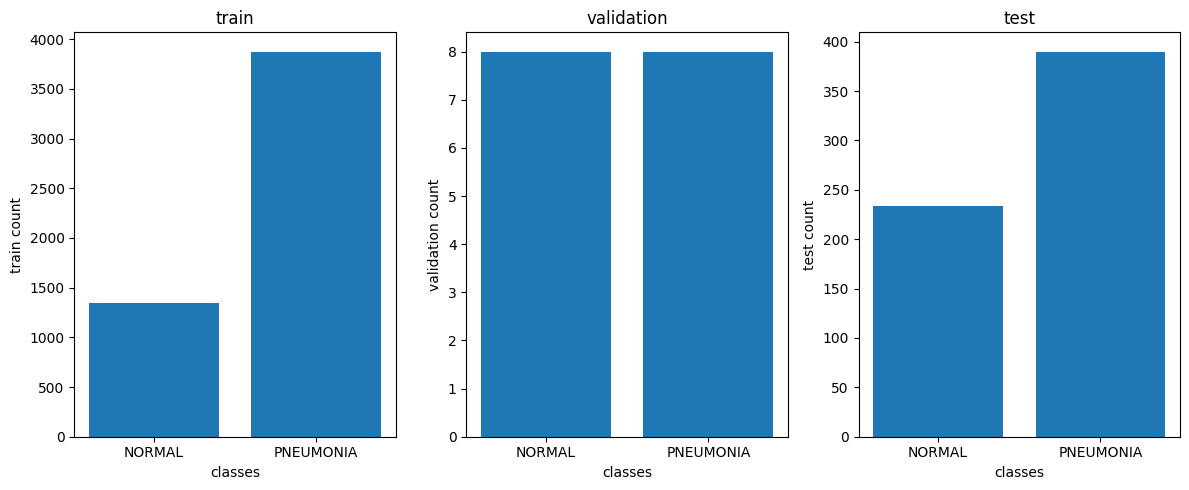

In [7]:

countes =  {
    "train": [len(train_image["normal"]), len(train_image["pneumonia"])],
    "validation": [len(val_image["normal"]), len(val_image["pneumonia"])],
    "test": [len(test_image["normal"]), len(test_image["pneumonia"])]
}

charts(countes)

## Identifier les éventuels problèmes

In [ ]:
def check_image(img_path):
    try:
        with Image.open(img_path) as img:
            img.verify()
            img.convert()
            return True 
    except:
        return False

In [9]:

train_valid = train_image
# {
#     cls: [img for img in train_image[cls] if check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

val_valid = val_image
# {
#     cls: [img for img in val_image[cls] if check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

test_valid =  test_image
# {
#     cls: [img for img in test_image[cls] if check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }



## Redimensionner les images et convertir au format RGB

In [ ]:

from tensorflow.keras.utils import img_to_array





def process_image(img):
    image = load_img(
        img,
        target_size=(180, 180),
        color_mode="rgb"
    )
    # if normalize:
    image = img_to_array(image) / 255.0
    image = np.asarray(image, dtype=np.float32)
    
    # else:    
    #     image = img_to_array(image)
    return image
    

In [11]:
train_processed = {
    cls: np.array([
        process_image(path)
        for path in train_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

val_processed = {
    cls: np.array([
        process_image(path)
        for path in val_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

test_processed = {
    cls: np.array([
        process_image(path)
        for path in test_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

## Préparer les images au format attendu par le modèle CNN

In [ ]:

# from tensorflow.keras.utils import img_to_array

# train_processed = {
#     cls: np.array([
#         img_to_array(path)
#         for path in train_redim[cls]
#     ], dtype=np.float32)
#     for cls in ["normal", "pneumonia"]
# }


# val_processed = {
#     cls: np.array([
#         img_to_array(path)
#         for path in val_redim[cls]
#     ], dtype=np.float32)
#     for cls in ["normal", "pneumonia"]
# }

# test_processed = {
#     cls: np.array([
#         img_to_array(path)
#         for path in test_redim[cls]
#     ], dtype=np.float32)
#     for cls in ["normal", "pneumonia"]
# }

## Associer les labels aux images

In [13]:
# Train
X_train = np.concatenate(
    (
        train_processed["normal"],
        train_processed["pneumonia"]
    ),
    axis=0
)
y_train = np.concatenate(
    (
        np.zeros(len(train_processed["normal"])),
        np.ones(len( train_processed["pneumonia"]))
    ),
    axis= 0
)

# Validation
X_val = np.concatenate(
    (
        val_processed["normal"], 
        val_processed["pneumonia"]
    ), 
    axis=0
)
y_val = np.concatenate(
    (
        np.zeros(len(val_processed["normal"])),
        np.ones(len( val_processed["pneumonia"]))
    ),
    axis= 0
)
# Test
X_test = np.concatenate(
    (
        test_processed["normal"], 
        test_processed["pneumonia"]
    ), 
    axis=0
)
y_test = np.concatenate(
    (
        np.zeros(len(test_processed["normal"])),
        np.ones(len( test_processed["pneumonia"]))
    ),
    axis=0
)


In [14]:
from sklearn.utils import shuffle

X_train, y_train = shuffle(X_train, y_train, random_state = 42)
X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)

## Normaliser les valeurs

In [ ]:

# X_train = np.asarray( [d/ 255 for d in X_train], dtype=np.float64)

# X_val = np.asarray([d/ 255 for d in X_val], dtype=np.float64)

# X_test = np.asarray([d/ 255 for d in X_test], dtype=np.float64)

## Visualiser un échantillon d'images

In [ ]:
# import matplotlib.pyplot as plt

# def display():
#     fig, axes = plt.subplots(2, 3, figsize=(10, 6))

#     for i in range(3):
#         axes[0, i].imshow(train_redim["normal"][i].astype("uint8"))
#         axes[0, i].set_title("normal")
#         axes[0, i].axis("off")

#         axes[1, i].imshow(train_redim["pneumonia"][i].astype("uint8"))
#         axes[1, i].set_title("pneumonia")
#         axes[1, i].axis("off")

#     plt.tight_layout()
#     plt.show()

## Étudier le déséquilibre

In [24]:
from sklearn.utils.class_weight import compute_class_weight
 
def equilbre():
    
    classes = np.unique(y_train)


    weights = compute_class_weight(class_weight="balanced", classes=classes, y = y_train)

    class_weights = dict(zip(classes, weights))
    
    print(class_weights)

    return class_weights

class_weights = equilbre()


{np.float32(0.0): np.float64(1.9448173005219984), np.float32(1.0): np.float64(0.6730322580645162)}


In [18]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    # Input images: height, width, RGB channels
    keras.Input(shape=(180, 180, 3)),

    # Feature extraction
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output: NORMAL or PNEUMONIA
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 118336)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    15,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,166,657 (57.86 MB)

 Trainable params: 15,166,657 (57.86 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)



In [20]:
import numpy as np
import time 



start= time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    class_weight = class_weights,
    validation_data=(X_val, y_val),
    callbacks = [early_stopping]
)

end = time.time()

training_duration = start - end

training_duration



Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.8666 - auc: 0.9379 - loss: 0.3778 - precision: 0.9538 - recall: 0.8622 - val_accuracy: 0.8125 - val_auc: 0.9531 - val_loss: 0.2568 - val_precision: 0.8571 - val_recall: 0.7500
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 254s 2s/step - accuracy: 0.9576 - auc: 0.9909 - loss: 0.1169 - precision: 0.9864 - recall: 0.9561 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1639 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9655 - auc: 0.9943 - loss: 0.0928 - precision: 0.9899 - recall: 0.9634 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1681 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9718 - auc: 0.9954 - loss: 0.0782 - precision: 0.9916 - recall: 0.9703 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.1813 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 5/5
163/163 ━━━━━━━━━━━━━━

-1298.6143598556519

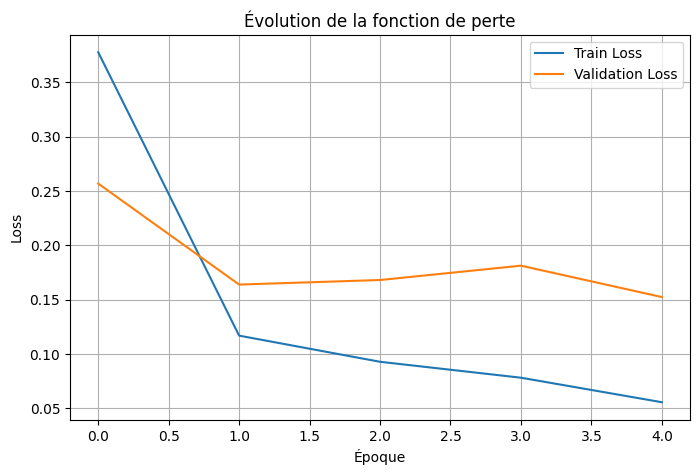

In [21]:

import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid(True)
plt.show()

# # Courbes d'accuracy
# plt.figure(figsize=(8, 5))
# plt.plot(history.history["accuracy"], label="Train Accuracy")
# plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
# plt.xlabel("Époque")
# plt.ylabel("Accuracy")
# plt.title("Évolution de l'accuracy")
# plt.legend()
# plt.grid(True)
# plt.show()


In [ ]:


from sklearn.metrics import f1_score, roc_auc_score


print(X_test.shape)

probabilities = model.predict(X_test, verbose=0).ravel()

y_pred = (probabilities >= 0.5).astype(int)

print("F1-score:", f1_score(y_test, y_pred))

scores = model.evaluate(X_test, y_test, return_dict = True)

print(scores)

roc_auc_score_ = roc_auc_score(y_test, y_pred)
print("roc_auc_score: ", roc_auc_score_)


(624, 180, 180, 3)
F1-score: 0.8629671574178935
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.8061 - auc: 0.9080 - loss: 0.7318 - precision: 0.7728 - recall: 0.9769
{'accuracy': 0.8060897588729858, 'auc': 0.9080045223236084, 'loss': 0.7317908406257629, 'precision': 0.772819459438324, 'recall': 0.9769230484962463}


np.float64(0.7491452991452991)

In [23]:

# one image
image = X_test[0]

true_label = y_test[0]

image_batch = np.expand_dims(image, axis=0)

probabilities = model.predict(image_batch)

# Convert probabilities into classes
predicted_class = "PNEUMONIA" if probabilities[0][0] <= 0.5 else "NORMAL"
y_pred = 1 if probabilities[0][0] <= 0.5 else 0


print("true label: ", true_label)
print("Probabilité prédite :", probabilities[0][0])
print("prédicted_label: ", y_pred)
print("Classe prédite :", predicted_class)

print("y_pred: ", y_pred)
    
f1 = f1_score([true_label], [y_pred], zero_division=0)

print("F1-score :", f1)




1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
true label:  0.0
Probabilité prédite : 0.949744
prédicted_label:  0
Classe prédite : NORMAL
y_pred:  0
F1-score : 0.0


# Automize

In [ ]:
cnn_model = keras.Sequential([
    # Input images: height, width, RGB channels
    keras.Input(shape=(None, None, 3)),
    
    layers.Resizing(180, 180),  # new layer, test it
    
    layers.Rescaling(1./255), # new layer, test it
     
    # Feature extraction
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output: NORMAL or PNEUMONIA
    layers.Dense(1, activation="sigmoid")
])

cnn_history = train_model_save(cnn_model, "cnn_model.keras", eta=1e-3, save=True)


In [ ]:
# import os
# from google.colab import drive


# path = "/content/pneumonia_model.keras"

# if os.path.exists(path):

#     drive.mount("/content/drive")
#     import shutil

#     shutil.copy(
#     "/content/pneumonia_model.keras",
#     "/content/drive/MyDrive/pneumonia_model.keras"
#     )


<!-- إلا كنتي كتقصد بـ pipeline استعمال tf.data مع cache(), prefetch() لتحسين سرعة التدريب، تقدر تزيد هاد التحسينات قبل model.fit(). -->

# MobileNetV2

In [11]:
base_model_tl = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)
base_model_tl.trainable = False

/tmp/ipykernel_1425/3571261794.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_tl = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [12]:
tl_model =  keras.Sequential([
    layers.Input((None, None, 3)),
    layers.Resizing(180, 180),
    layers.Rescaling(scale=1./127.5, offset=-1.),
    base_model_tl,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

In [13]:
tl_history = train_model_save(tl_model, "tl_model.keras", save=True)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 117ms/step - accuracy: 0.7369 - auc: 0.8136 - loss: 0.4997 - precision: 0.8844 - recall: 0.7236 - val_accuracy: 0.9442 - val_auc: 0.9888 - val_loss: 0.1529 - val_precision: 0.9820 - val_recall: 0.9422 - learning_rate: 0.0010
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - accuracy: 0.9442 - auc: 0.9883 - loss: 0.1533 - precision: 0.9905 - recall: 0.9329 - val_accuracy: 0.9576 - val_auc: 0.9929 - val_loss: 0.1217 - val_precision: 0.9898 - val_recall: 0.9528 - learning_rate: 0.0010
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.9567 - auc: 0.9923 - loss: 0.1202 - precision: 0.9897 - recall: 0.9513 - val_accuracy: 0.9626 - val_auc: 0.9946 - val_loss: 0.1111 - val_precision: 0.9928 - val_recall: 0.9566 - learning_rate: 0.0010
Epoch 4/5
  4/163 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.9368 - auc: 0.9941 - loss: 0.1310 - precision: 0.9968 - recall: 0.9102 

2026-10-20 20:44:11.922975: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 33554944 bytes after encountering the first element of size 33554944 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


163/163 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - accuracy: 0.9545 - auc: 0.9933 - loss: 0.1092 - precision: 0.9908 - recall: 0.9467 - val_accuracy: 0.9705 - val_auc: 0.9955 - val_loss: 0.0877 - val_precision: 0.9897 - val_recall: 0.9703 - learning_rate: 0.0010
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.9668 - auc: 0.9947 - loss: 0.0962 - precision: 0.9897 - recall: 0.9648 - val_accuracy: 0.9724 - val_auc: 0.9962 - val_loss: 0.0821 - val_precision: 0.9916 - val_recall: 0.9711 - learning_rate: 0.0010


# Fine-Tuning

In [ ]:
ft_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)
ft_base_model.trainable = True

for layer in ft_base_model.layers[:-30]:
    layer.trainable = False

In [15]:


ft_model =  keras.Sequential([
    layers.Input((None, None, 3)),
    layers.Resizing(180, 180),
    layers.Rescaling(scale=1./127.5, offset=-1.),
    ft_base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

In [ ]:
ft_history =  train_model_save(ft_model, "ft_model.keras", eta=1e-7, save=True)

# Evaluate

In [ ]:

y_test = np.concatenate([
    labels.numpy() for images, labels in test_ds
]).ravel()

def predict_xray(model):
    
    probabilities = model.predict(test_ds, verbose=0).ravel()

    y_pred = (probabilities >= 0.5).astype(int)
    
    return y_pred

def metrics(y_pred, model):
    # roc_auc_score_ = roc_auc_score(y_test, y_pred)
    
    f1 =  f1_score(y_test, y_pred)
    
    scores = model.evaluate(test_ds, return_dict = True)
    
    return scores["accuracy"], scores["loss"], scores["recall"], scores["precision"], scores["auc"], f1

def compare_metrics_epochs(history):
    accuracy = np.array(history.history["accuracy"])
    loss = np.array(history.history["loss"])
    recall = np.array(history.history["recall"])
    precision = np.array(history.history["precision"])
    auc = np.array(history.history["auc"])
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)

    return accuracy, loss, recall, precision, auc, f1

In [31]:
def plot_metrics(cnn_metric, tl_metric, ft_metric, metric_name, bar_title):
    models = ["CNN", "Transfer Learning", "Fine-Tuning"]
    values = [cnn_metric, tl_metric, ft_metric]

    plt.bar(models, values, label=metric_name)

    plt.title(bar_title)
    plt.xlabel("Models")
    plt.ylabel(metric_name)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.show()
    
cnn_accuracy, cnn_loss, cnn_recall, cnn_precision, cnn_auc,cnn_f1 = metrics(predict_xray(cnn_model), cnn_model)
tl_accuracy, tl_loss, tl_recall, tl_precision, tl_auc, tl_f1 = metrics(predict_xray(tl_model), tl_model)
ft_accuracy, ft_loss, ft_recall, ft_precision, ft_auc,ft_f1 = metrics(predict_xray(ft_model), ft_model)




163/163 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.9893 - auc: 0.9996 - loss: 0.0324 - precision: 0.9994 - recall: 0.9859
163/163 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - accuracy: 0.9730 - auc: 0.9966 - loss: 0.0805 - precision: 0.9930 - recall: 0.9696
163/163 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - accuracy: 0.6800 - auc: 0.7935 - loss: 0.6019 - precision: 0.8940 - recall: 0.6399


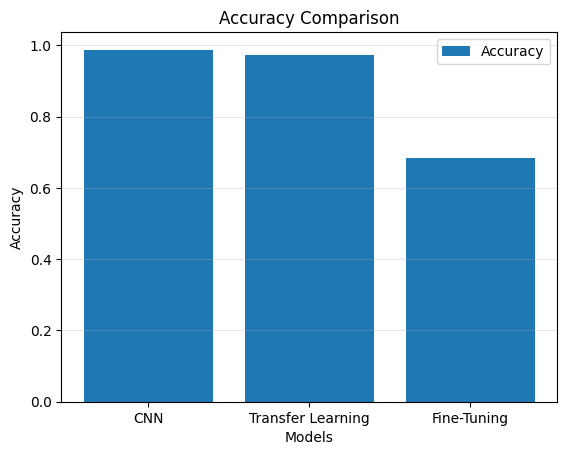

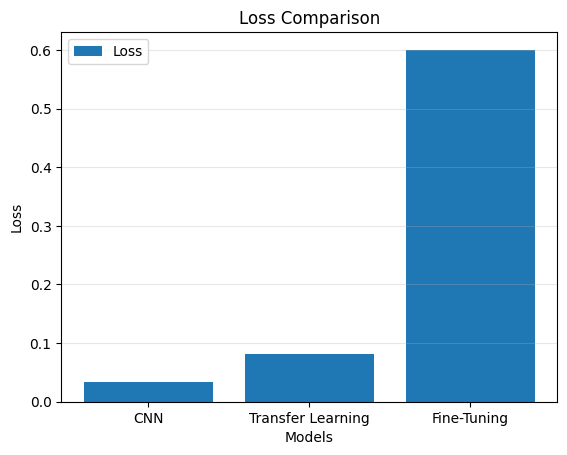

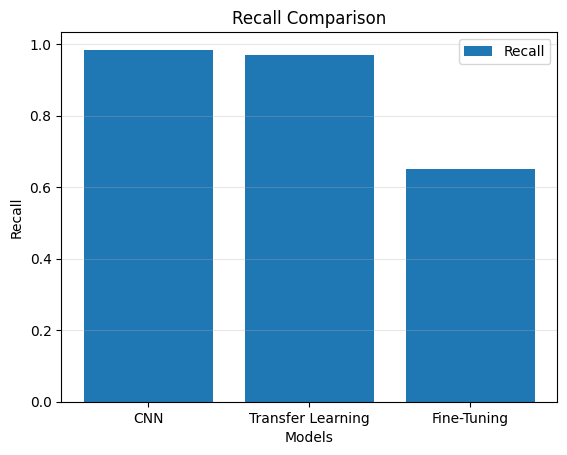

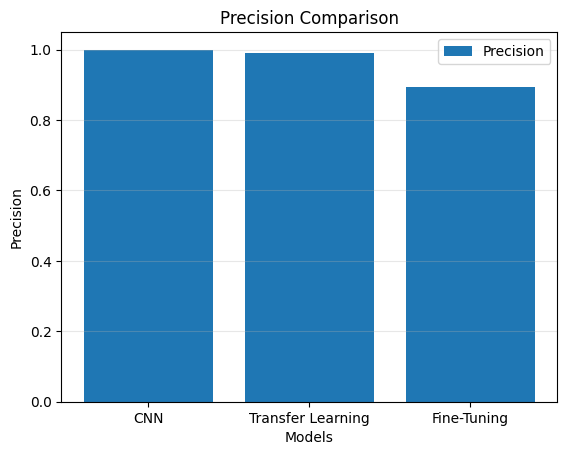

In [32]:
plot_metrics(cnn_accuracy, tl_accuracy, ft_accuracy, "Accuracy", "Accuracy Comparison")
plot_metrics(cnn_loss, tl_loss, ft_loss, "Loss", "Loss Comparison")
plot_metrics(cnn_recall, tl_recall, ft_recall, "Recall", "Recall Comparison")
plot_metrics(cnn_precision, tl_precision, ft_precision, "Precision", "Precision Comparison")
# plot_metrics(cnn_f1, tl_f1, ft_f1, "F1", "F1 Comparison")    

In [30]:
print("CNN Model Metrics:")
print(f"Accuracy: {cnn_accuracy:.4f}, Loss: {cnn_loss:.4f}, Recall: {cnn_recall:.4f}, Precision: {cnn_precision:.4f}, AUC: {cnn_auc:.4f}, F1: {cnn_f1:.4f}")

print("TL Model Metrics:")
print(f"Accuracy: {tl_accuracy:.4f}, Loss: {tl_loss:.4f}, Recall: {tl_recall:.4f}, Precision: {tl_precision:.4f}, AUC: {tl_auc:.4f}, F1: {tl_f1:.4f}")

print("FT Model Metrics:")
print(f"Accuracy: {ft_accuracy:.4f}, Loss: {ft_loss:.4f}, Recall: {ft_recall:.4f}, Precision: {ft_precision:.4f}, AUC: {ft_auc:.4f}, F1: {ft_f1:.4f}")

CNN Model Metrics:
Accuracy: 0.9879, Loss: 0.0329, Recall: 0.9843, Precision: 0.9995, AUC: 0.9996, F1: 0.7318
TL Model Metrics:
Accuracy: 0.9722, Loss: 0.0822, Recall: 0.9708, Precision: 0.9916, AUC: 0.9962, F1: 0.7370
FT Model Metrics:
Accuracy: 0.6839, Loss: 0.6003, Recall: 0.6516, Precision: 0.8941, AUC: 0.7899, F1: 0.6243


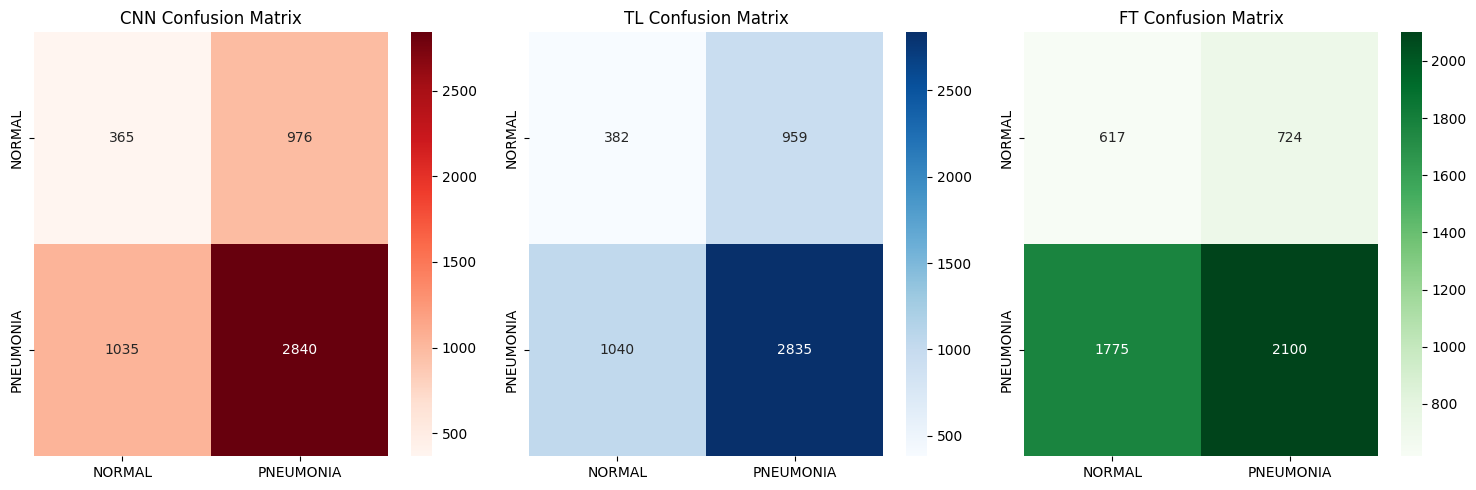

In [28]:
cnn_cm = confusion_matrix(y_test, predict_xray(cnn_model))
tl_cm = confusion_matrix(y_test, predict_xray(tl_model))
ft_cm = confusion_matrix(y_test, predict_xray(ft_model))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].set_title("CNN Confusion Matrix")
sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"],
    ax=axes[0]
)



axes[1].set_title("TL Confusion Matrix")
sns.heatmap(
    tl_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"],
    ax=axes[1]
)

axes[2].set_title("FT Confusion Matrix")
sns.heatmap(
    ft_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"],
    ax=axes[2]
)

plt.tight_layout()

plt.show()